### Step-1: Importing Necessary Libraries

In [42]:
# Data analysis and Manipulation
import plotly.graph_objs as go
import plotly.io as pio
import plotly.express as px
import pandas as pd

# Data Visualization
import matplotlib.pyplot as plt

# Importing Plotly
import plotly.offline as py
py.init_notebook_mode(connected=True)

# Initialization Plotly
pio.renderers.default = 'colab'

### Step-2: Importing Datasets

In [43]:
# Importing Dataset1
dataset1 = pd.read_csv("/kaggle/input/datasets/tahsinhaqueruhin/covid-19/covid.csv")
dataset1.head()

,Country/Region,Continent,Population,TotalCases,NewCases,TotalDeaths,NewDeaths,TotalRecovered,NewRecovered,ActiveCases,"Serious,Critical",Tot Cases/1M pop,Deaths/1M pop,TotalTests,Tests/1M pop,WHO Region,iso_alpha
0,USA,North America,3.311981e+08,5032179,NaN,162804.0,NaN,2576668.0,NaN,2292707.0,18296.0,15194.0,492.0,63139605.0,190640.0,Americas,USA
1,Brazil,South America,2.127107e+08,2917562,NaN,98644.0,NaN,2047660.0,NaN,771258.0,8318.0,13716.0,464.0,13206188.0,62085.0,Americas,BRA
2,India,Asia,1.381345e+09,2025409,NaN,41638.0,NaN,1377384.0,NaN,606387.0,8944.0,1466.0,30.0,22149351.0,16035.0,South-EastAsia,IND
3,Russia,Europe,1.459409e+08,871894,NaN,14606.0,NaN,676357.0,NaN,180931.0,2300.0,5974.0,100.0,29716907.0,203623.0,Europe,RUS
4,South Africa,Africa,5.938157e+07,538184,NaN,9604.0,NaN,387316.0,NaN,141264.0,539.0,9063.0,162.0,3149807.0,53044.0,Africa,ZAF


In [44]:
# Example: Getting dataset information
# Returns tuple of shape (Rows, Columns)
print(dataset1.shape)

# Returns size of the dataframe
print(dataset1.size)

(209, 17)
3553


In [45]:
# Information about dataset1
# Return the summary of dataframe
dataset1.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 209 entries, 0 to 208
Data columns (total 17 columns):
 #   Column            Non-Null Count  Dtype  
---  ------            --------------  -----  
 0   Country/Region    209 non-null    object 
 1   Continent         208 non-null    object 
 2   Population        208 non-null    float64
 3   TotalCases        209 non-null    int64  
 4   NewCases          4 non-null      float64
 5   TotalDeaths       188 non-null    float64
 6   NewDeaths         3 non-null      float64
 7   TotalRecovered    205 non-null    float64
 8   NewRecovered      3 non-null      float64
 9   ActiveCases       205 non-null    float64
 10  Serious,Critical  122 non-null    float64
 11  Tot Cases/1M pop  208 non-null    float64
 12  Deaths/1M pop     187 non-null    float64
 13  TotalTests        191 non-null    float64
 14  Tests/1M pop      191 non-null    float64
 15  WHO Region        184 non-null    object 
 16  iso_alpha         209 non-null    object 
dt

In [46]:
# Importing dataset2
dataset2 = pd.read_csv("/kaggle/input/datasets/tahsinhaqueruhin/covid-19/covid_grouped.csv")
dataset2.head()

,Date,Country/Region,Confirmed,Deaths,Recovered,Active,New cases,New deaths,New recovered,WHO Region,iso_alpha
0,2020-01-22,Afghanistan,0,0,0,0,0,0,0,Eastern Mediterranean,AFG
1,2020-01-22,Albania,0,0,0,0,0,0,0,Europe,ALB
2,2020-01-22,Algeria,0,0,0,0,0,0,0,Africa,DZA
3,2020-01-22,Andorra,0,0,0,0,0,0,0,Europe,AND
4,2020-01-22,Angola,0,0,0,0,0,0,0,Africa,AGO


In [47]:
# Getting dataset2 information
print(dataset2.shape)
print(dataset2.size)
dataset2.info()

(35156, 11)
386716
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 35156 entries, 0 to 35155
Data columns (total 11 columns):
 #   Column          Non-Null Count  Dtype 
---  ------          --------------  ----- 
 0   Date            35156 non-null  object
 1   Country/Region  35156 non-null  object
 2   Confirmed       35156 non-null  int64 
 3   Deaths          35156 non-null  int64 
 4   Recovered       35156 non-null  int64 
 5   Active          35156 non-null  int64 
 6   New cases       35156 non-null  int64 
 7   New deaths      35156 non-null  int64 
 8   New recovered   35156 non-null  int64 
 9   WHO Region      35156 non-null  object
 10  iso_alpha       35156 non-null  object
dtypes: int64(7), object(4)
memory usage: 3.0+ MB


### Step-3: Dataset Cleaning

In [48]:
# Columns Labels of a Dataset1
dataset1.columns

Index(['Country/Region', 'Continent', 'Population', 'TotalCases', 'NewCases',
       'TotalDeaths', 'NewDeaths', 'TotalRecovered', 'NewRecovered',
       'ActiveCases', 'Serious,Critical', 'Tot Cases/1M pop', 'Deaths/1M pop',
       'TotalTests', 'Tests/1M pop', 'WHO Region', 'iso_alpha'],
      dtype='object')

In [49]:
# Drop Newcases, NewDeaths, NewRecovered rows from dataset1 as they have NaN values
dataset1.drop(['NewCases', 'NewDeaths', 'NewRecovered'], 
             axis=1, inplace=True)

# Select random set of values from dataset1
dataset1.sample(5)

,Country/Region,Continent,Population,TotalCases,TotalDeaths,TotalRecovered,ActiveCases,"Serious,Critical",Tot Cases/1M pop,Deaths/1M pop,TotalTests,Tests/1M pop,WHO Region,iso_alpha
174,Cambodia,Asia,16741375.0,243,NaN,210.0,33.0,1.0,15.0,NaN,67807.0,4050.0,WesternPacific,KHM
64,Austria,Europe,9011577.0,21696,719.0,19596.0,1381.0,25.0,2408.0,80.0,937275.0,104008.0,Europe,AUT
6,Peru,South America,33016319.0,455409,20424.0,310337.0,124648.0,1426.0,13793.0,619.0,2493429.0,75521.0,Americas,PER
5,Mexico,North America,129066160.0,462690,50517.0,308848.0,103325.0,3987.0,3585.0,391.0,1056915.0,8189.0,Americas,MEX
63,Nepal,Asia,29186486.0,21750,65.0,15389.0,6296.0,NaN,745.0,2.0,731977.0,25079.0,South-EastAsia,NPL


### Example: Create table using plotly express

In [50]:
# Import create_table Figure Factory

from plotly.figure_factory import create_table

colorscale = [[0, '#4d004c'], [.5, '#f2e5ff'], [1, '#ffffff']]
table = create_table(dataset1.head(15), colorscale=colorscale)
py.iplot(table)

### Step 4: Bar graphs- Comparisons between COVID infected countries in terms of total cases, total deaths, total recovered & total tests


In [51]:
px.bar(dataset1.head(15), x = 'Country/Region',
      y = 'TotalCases', color = 'TotalCases',
      height = 500, hover_data = ['Country/Region', 'Continent'])

As the plot clearly shows the data for the top 15 countries, now again take the country with respect to the total number of cases from the top 15 countries, color the total deaths hover data as 'Country/Region', 'Continent' and analyze the visualization.

In [52]:
px.bar(dataset1.head(15), x = 'Country/Region', 
       y = 'TotalCases', color = 'TotalDeaths',
       height = 500, hover_data = ['Country/Region', 'Continent'])

### Let's analyze by coloring the total number of Total Tests

In [53]:
px.bar(dataset1.head(15), x = 'Country/Region', y = 'TotalCases',
       color = 'TotalTests', height = 500,
       hover_data = ['Country/Region', 'Continent'])

In [54]:
# Horizontal Orientation Plot
px.bar(dataset1.head(15), x = 'TotalTests',
      y = 'Country/Region', color = 'TotalTests', orientation = 'h',
      height = 500, hover_data = ['Country/Region', 'Continent'])

In [55]:
# Let's look at 'TotalTests' followed by 'Continent' and color the plot with 'Continent'.
px.bar(dataset1.head(15), x = 'TotalTests', y = 'Continent',
      color = 'TotalTests', orientation = 'h', height = 500,
      hover_data = ['Country/Region', 'Continent'])

### Step 5: Data Visualization through Bubble Charts-Continent Wise

In [56]:
px.scatter(dataset1, x='Continent', y='TotalCases',
          hover_data=['Country/Region', 'Continent'],
          color='TotalCases', size='TotalCases', size_max=80)

In [57]:
px.scatter(dataset1.head(60), x='Continent', y='TotalCases',
          hover_data=['Country/Region', 'Continent'],
          color='TotalCases', size='TotalCases', size_max=80,
          log_y=True)

In [58]:
px.scatter(dataset1.head(54), x='Continent',y='TotalTests', 
          hover_data=['Country/Region', 'Continent'],
          color='TotalTests', size='TotalTests', size_max=80)

In [59]:
px.scatter(dataset1.head(50), x='Continent',y='TotalTests', 
          hover_data=['Country/Region', 'Continent'],
          color='TotalTests', size='TotalTests', size_max=80,
          log_y=True)

### Step 6: Data Visualization through Bubble Charts-Country Wise

In [60]:
px.scatter(dataset1.head(100), x='Country/Region', y='TotalCases',
          hover_data=['Country/Region', 'Continent'],
          color='TotalCases', size='TotalCases', size_max=80)

### Example: Bubble chart

In [61]:
px.scatter(dataset1.head(30), x='Country/Region', y='TotalCases',
          hover_data=['Country/Region', 'Continent'],
          color='Country/Region', size='TotalCases', size_max=80,
          log_y=True)

In [62]:
px.scatter(dataset1.head(10), x='Country/Region', y='TotalDeaths',
          hover_data=['Country/Region', 'Continent'],
          color='Country/Region', size='TotalDeaths', size_max=80)

In [63]:
# Example: Country/Region VS Tests/1M pop (color-scale of Tests/1M pop)
px.scatter(dataset1.head(30), x='Country/Region', y='Tests/1M pop',
          hover_data=['Country/Region', 'Continent'],
          color='Tests/1M pop', size='Tests/1M pop', size_max=80)

In [64]:
px.scatter(dataset1.head(30), x='TotalCases', y='TotalDeaths', 
          hover_data=['Country/Region', 'Continent'],
          color='TotalDeaths', size='TotalDeaths', size_max=80)

In [65]:
px.scatter(dataset1.head(30), x='TotalCases', y='TotalDeaths',
          hover_data=['Country/Region', 'Continent'],
          color='TotalDeaths', size='TotalDeaths', size_max=80,
          log_x=True, log_y=True)

### Step 7: Advanced Data Visualization- Bar graphs for All top infected Countries

In [66]:
px.bar(dataset2, x="Date", y="Confirmed", color="Confirmed",
      hover_data=["Confirmed", "Date", "Country/Region"],
      height=400)

In [67]:
px.bar(dataset2, x="Date", y="Confirmed", color="Confirmed",
      hover_data=["Confirmed", "Date", "Country/Region"], log_y=True,
      height=400)

In [68]:
px.bar(dataset2, x="Date", y="Deaths", color="Deaths",
      hover_data=["Confirmed", "Date", "Country/Region"],
      log_y=False, height=400)

### Step 8: Countries Specific COVID Data Visualization: (United States)

In [69]:
# Example: Refining dataset to get only USA data
df_US = dataset2.loc[dataset2["Country/Region"]=="US"]

In [70]:
px.bar(df_US, x="Date", y="Confirmed", color="Confirmed", height=400)

In [71]:
px.bar(df_US, x="Date", y="Recovered", color="Recovered", height=400)

In [72]:
# Example: Line Plot
px.line(df_US, x="Date", y="Recovered", height=400)

In [73]:
px.line(df_US, x="Date", y="Deaths", height=400)

In [74]:
px.line(df_US, x="Date", y="Confirmed", height=400)

In [75]:
px.line(df_US, x="Date", y="New cases", height=400)

In [76]:
px.bar(df_US, x="Date", y="New cases", height=400)

In [77]:
px.scatter(df_US, x="Confirmed", y="Deaths", height=400)

### Step 9: Visualization of Data in terms of Maps

In [78]:
px.choropleth(dataset2,
             locations="iso_alpha",
             color="Confirmed",
             hover_name="Country/Region",
             color_continuous_scale="Blues",
             animation_frame="Date")

In [79]:
px.choropleth(dataset2, 
             locations='iso_alpha',
             color="Recovered",
             hover_name="Country/Region",
             color_continuous_scale="RdYlGn",
             projection="natural earth",
             animation_frame="Date")

In [ ]:
px.bar(dataset2, x="WHO Region", y="Confirmed", color="WHO Region",
      animation_frame="Date", hover_name="Country/Region")

### Step 10: Visualize text using Word Cloud

In [82]:
dataset3 = pd.read_csv("/kaggle/input/datasets/tahsinhaqueruhin/covid-19/coviddeath.csv")
dataset3.head()

,Data as of,Start Week,End Week,State,Condition Group,Condition,ICD10_codes,Age Group,Number of COVID-19 Deaths,Flag
0,08/30/2020,02/01/2020,08/29/2020,US,Respiratory diseases,Influenza and pneumonia,J09-J18,0-24,122.0,NaN
1,08/30/2020,02/01/2020,08/29/2020,US,Respiratory diseases,Influenza and pneumonia,J09-J18,25-34,596.0,NaN
2,08/30/2020,02/01/2020,08/29/2020,US,Respiratory diseases,Influenza and pneumonia,J09-J18,35-44,1521.0,NaN
3,08/30/2020,02/01/2020,08/29/2020,US,Respiratory diseases,Influenza and pneumonia,J09-J18,45-54,4186.0,NaN
4,08/30/2020,02/01/2020,08/29/2020,US,Respiratory diseases,Influenza and pneumonia,J09-J18,55-64,10014.0,NaN


In [84]:
dataset3.tail()

,Data as of,Start Week,End Week,State,Condition Group,Condition,ICD10_codes,Age Group,Number of COVID-19 Deaths,Flag
12255,08/30/2020,02/01/2020,08/29/2020,YC,Coronavirus Disease 2019,COVID-19,U071,65-74,5024.0,NaN
12256,08/30/2020,02/01/2020,08/29/2020,YC,Coronavirus Disease 2019,COVID-19,U071,75-84,5381.0,NaN
12257,08/30/2020,02/01/2020,08/29/2020,YC,Coronavirus Disease 2019,COVID-19,U071,85+,4841.0,NaN
12258,08/30/2020,02/01/2020,08/29/2020,YC,Coronavirus Disease 2019,COVID-19,U071,Not stated,NaN,Counts less than 10 suppressed.
12259,08/30/2020,02/01/2020,08/29/2020,YC,Coronavirus Disease 2019,COVID-19,U071,All ages,20628.0,NaN


In [85]:
dataset3.groupby(["Condition"]).count()

,Data as of,Start Week,End Week,State,Condition Group,ICD10_codes,Age Group,Number of COVID-19 Deaths,Flag
Condition,,,,,,,,,
Adult respiratory distress syndrome,540,540,540,540,540,540,540,272,268
All other conditions and causes (residual),540,540,540,540,540,540,540,363,177
Alzheimer disease,530,530,530,530,530,530,530,144,386
COVID-19,540,540,540,540,540,540,540,377,163
Cardiac arrest,520,520,520,520,520,520,520,219,301
Cardiac arrhythmia,540,540,540,540,540,540,540,192,348
Cerebrovascular diseases,530,530,530,530,530,530,530,187,343
Chronic lower respiratory diseases,540,540,540,540,540,540,540,229,311
Diabetes,540,540,540,540,540,540,540,276,264


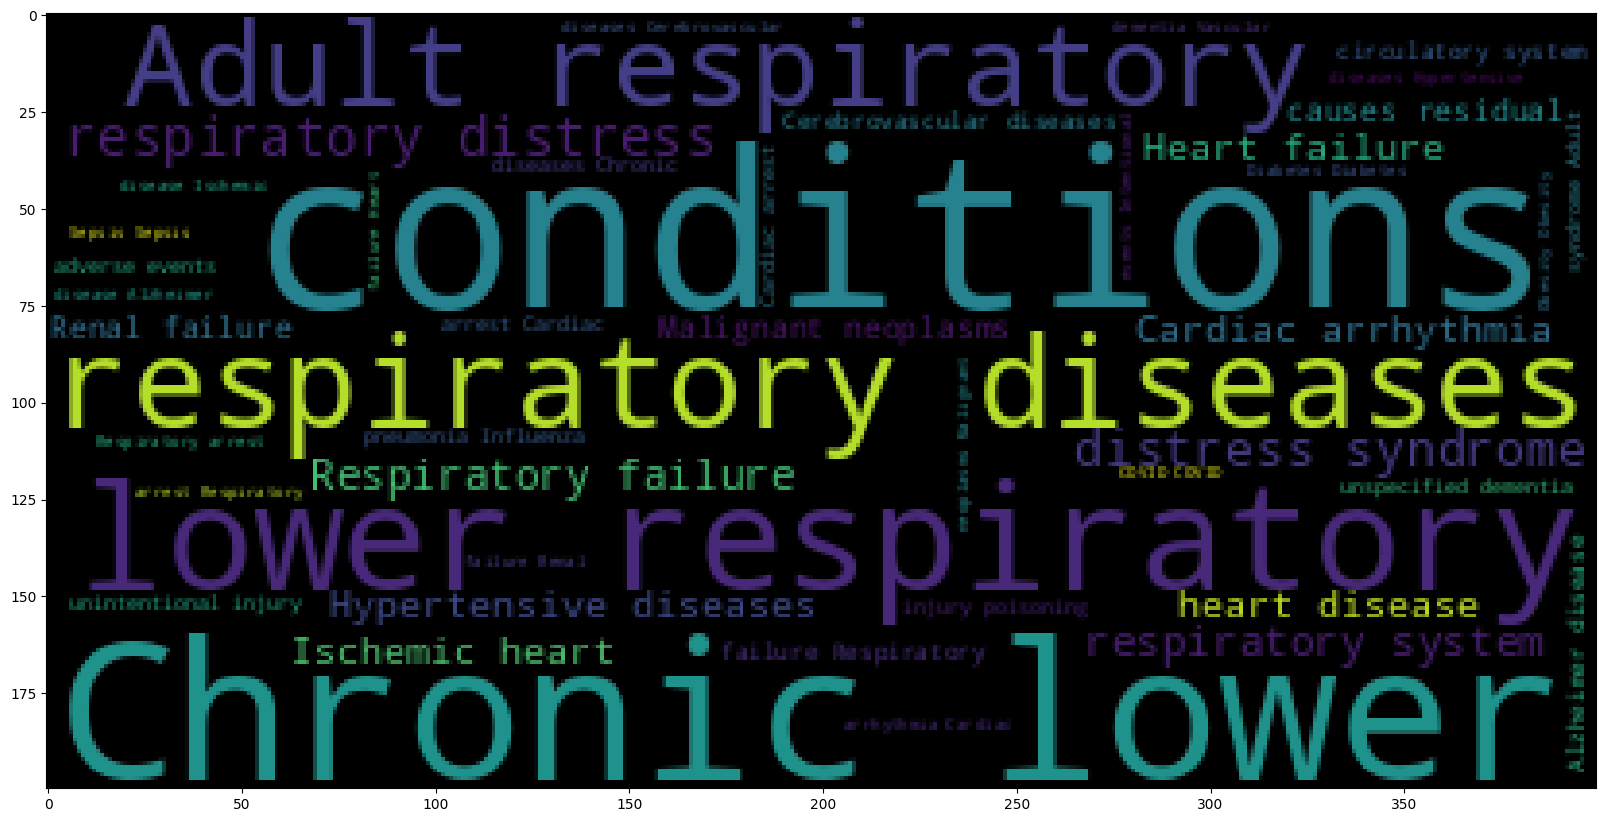

In [86]:
# Example: Create Wordcloud
# import word cloud
from wordcloud import WordCloud

sentences = dataset3["Condition"].tolist()
sentences_as_a_string = ' '.join(sentences)

# Convert the string into WordCloud
plt.figure(figsize=(20, 20))
plt.imshow(WordCloud().generate(sentences_as_a_string))

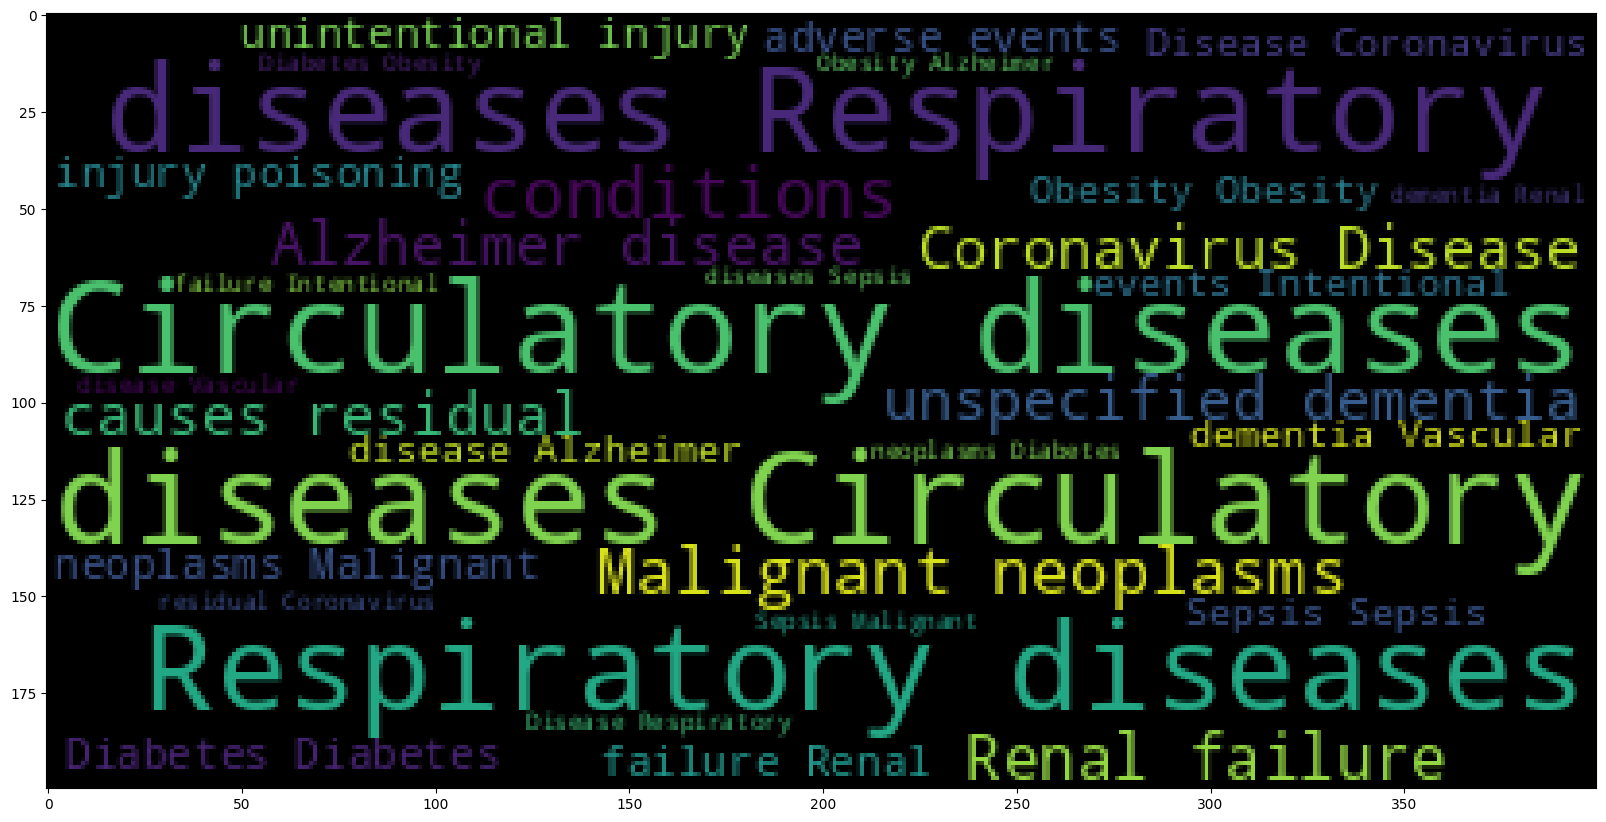

In [87]:
column2_tolist= dataset3["Condition Group"].tolist()

# Convert the list to one single string
column_to_string= " ".join(column2_tolist)

# Convert the string into WordCloud
plt.figure(figsize=(20, 20))
plt.imshow(WordCloud().generate(column_to_string))